In [1]:
import sys
sys.path.insert(0, "..")
import check_auc
import player_performance_prototype as p

# Held-out evaluation: split by match_id, build the score reference from train
# matches only, then score test matches with the API's own scoring code.
matches = check_auc.load_matches(check_auc.DATA_DIR)
train, test = check_auc.split_matches(matches, test_size=0.3, seed=0)
print(f"train matches={len(train)} test matches={len(test)} overlap=0")
scores, wins, roles = check_auc.score_matches(test, check_auc.build_reference(train))
for name, auc in check_auc.auc_report(scores, wins, roles).items():
    print(name, auc)

C:\Users\HARDPC\AppData\Local\Programs\Python\Python312\Lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.7.0) or chardet (7.6.0)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(


train matches=2273 test matches=975 overlap=0


ALL 0.789199789052078
TOP 0.7726751583914323
JUNGLE 0.844310065194245
MIDDLE 0.7761115558203011
BOTTOM 0.8064223102832058
UTILITY 0.7444464406959006


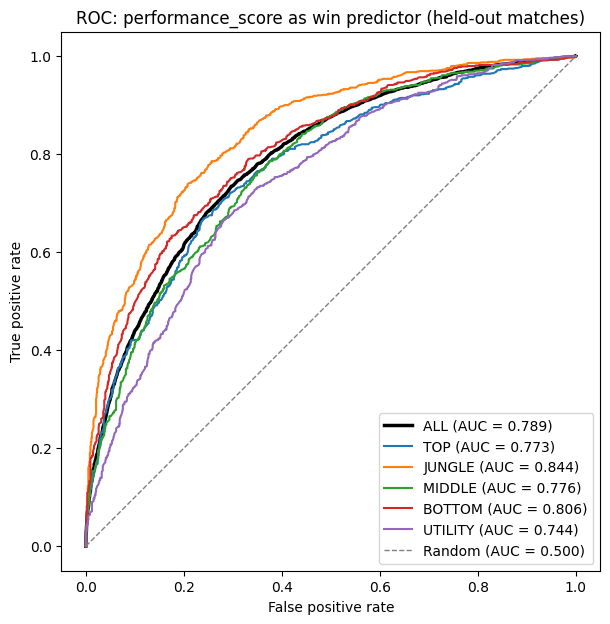

In [2]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve

fig, ax = plt.subplots(figsize=(7, 7))
fpr, tpr, _ = roc_curve(wins, scores)
ax.plot(fpr, tpr, color="black", lw=2.5, label=f"ALL (AUC = {roc_auc_score(wins, scores):.3f})")
for role in check_auc.ROLES:
    mask = roles == role
    fpr, tpr, _ = roc_curve(wins[mask], scores[mask])
    ax.plot(fpr, tpr, lw=1.5, label=f"{role} (AUC = {roc_auc_score(wins[mask], scores[mask]):.3f})")
ax.plot([0, 1], [0, 1], "--", color="grey", lw=1, label="Random (AUC = 0.500)")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC: performance_score as win predictor (held-out matches)")
ax.set_aspect("equal")
ax.legend(loc="lower right")
fig.savefig(p.OUTPUT_DIR / "roc_curves.png", dpi=160, bbox_inches="tight")
plt.show()